Re-run this notebook from anywhere inside the repository with:

```bash
(cd "$(git rev-parse --show-toplevel)" && uv run --no-project --with jupyter --with pyyaml --with pandas --with numpy --with scipy --with matplotlib --with openai --with python-dotenv --with requests jupyter nbconvert --to notebook --execute --inplace explorations/notebooks/04_evaluation_study.ipynb)
```

# 04 · Evaluation study pack

Worked examples on **toy data only** (no real labels, no dev-set predictions), each explained
the way I would defend it in front of the panel. Every number written to `04_results.json` is
computed in this notebook.

Contents: precision, recall and F1 · macro against micro F1 with tiny categories · restricted F1 ·
a 3x3 disposition confusion matrix · the Wilson interval · bootstrap intervals · McNemar for two
classifiers on the same items · the minimum detectable difference at N=65 · calibration (Brier
score, expected calibration error, reliability diagram) · prevalence, base rate and positive
predictive value · a simulation of selection bias when picking the best of many variants.

In [1]:
from __future__ import annotations

import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "policy-docs").is_dir())
EXP = REPO / "explorations"
rng = np.random.default_rng(20261007)
RESULTS: dict = {}

## 1. Precision, recall and F1

For one class (say *restricted = true*):

- **Precision** = TP / (TP + FP): of the items I called restricted, how many really were. Low
  precision means false alarms, which is what buried the old keyword system's reviewers.
- **Recall** = TP / (TP + FN): of the items that really were restricted, how many I caught. Low
  recall means violations walk through.
- **F1** = 2PR / (P + R), the harmonic mean: it is only high when both are high, and it ignores
  true negatives, which is right when the positive class is the rare one we care about.

In [2]:
def prf(tp: int, fp: int, fn: int) -> tuple[float, float, float]:
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    f = 2 * p * r / (p + r) if p + r else 0.0
    return p, r, f


toy = {"tp": 18, "fp": 4, "fn": 3}
p, r, f = prf(**toy)
print(f"toy restricted counts {toy}: precision {p:.3f}, recall {r:.3f}, F1 {f:.3f}")

toy restricted counts {'tp': 18, 'fp': 4, 'fn': 3}: precision 0.818, recall 0.857, F1 0.837


## 2. Macro against micro F1 when categories are tiny

**Micro F1** pools every item: with single-label classification it equals accuracy, so big
categories dominate. **Macro F1** is the mean of per-category F1, so every category weighs the
same however few items it has. The brief asks for macro F1 over the categories in the answers.

With 65 items over ~20 categories, many categories have one to four items. One item can move a
category's F1 from 1.0 to 0.0; with K categories that alone moves macro F1 by 1/K, while micro
F1 moves by 1/N. The toy below shows it.

In [3]:
cats = {
    "food_beverage": 20,
    "alcohol": 8,
    "lodging": 6,
    "ground_transport": 6,
    "computer_accessory": 5,
    "office_supplies": 4,
    "household_goods": 3,
    "personal_care": 3,
    "clothing": 2,
    "gift_card": 2,
    "jewelry": 1,
    "tobacco": 1,
    "gambling": 1,
    "laundry_service": 1,
    "airfare": 2,
}
y_true = [c for c, n in cats.items() for _ in range(n)]
y_pred = list(y_true)


def macro_micro(t: list[str], pr: list[str]) -> tuple[float, float, pd.DataFrame]:
    labels = sorted(set(t))
    rows = []
    for c in labels:
        tp = sum(a == c and b == c for a, b in zip(t, pr))
        fp = sum(a != c and b == c for a, b in zip(t, pr))
        fn = sum(a == c and b != c for a, b in zip(t, pr))
        rows.append((c, sum(a == c for a in t), *prf(tp, fp, fn)))
    df = pd.DataFrame(rows, columns=["category", "n", "precision", "recall", "f1"])
    micro = sum(a == b for a, b in zip(t, pr)) / len(t)
    return df["f1"].mean(), micro, df


base_macro, base_micro, _ = macro_micro(y_true, y_pred)
flip = list(y_pred)
flip[y_true.index("jewelry")] = "clothing"  # one jewelry item misread as clothing
flip_macro, flip_micro, flip_df = macro_micro(y_true, flip)
print(f"N={len(y_true)}, {len(cats)} categories")
print(f"perfect: macro {base_macro:.3f}, micro {base_micro:.3f}")
print(
    f"one item flipped: macro {flip_macro:.3f} (-{base_macro - flip_macro:.3f}), "
    f"micro {flip_micro:.3f} (-{base_micro - flip_micro:.3f})"
)
print(f"macro drop / micro drop = {(base_macro - flip_macro) / (base_micro - flip_micro):.1f}")
flip_df[flip_df["f1"] < 1]

N=65, 15 categories
perfect: macro 1.000, micro 1.000
one item flipped: macro 0.920 (-0.080), micro 0.985 (-0.015)
macro drop / micro drop = 5.2


,category,n,precision,recall,f1
2,clothing,2,0.666667,1.0,0.8
9,jewelry,1,0.000000,0.0,0.0


The single mistake zeroes `jewelry` (one item) **and** lowers `clothing` precision, so macro
drops several times as much as micro (ratio printed below). When I report macro F1 on 65 items I also show the
per-category table with each category's N, otherwise the number is unreadable.

## 3. Restricted F1

The engine consumes the restricted flag, so the binary decision matters on its own: positive
class *restricted = true*. A confusion between two restricted categories (jewelry and clothing)
costs macro F1 but **not** restricted F1; a confusion across the boundary (rum cake as alcohol)
costs both. That is why both metrics are required.

In [4]:
RESTRICTED = {
    "alcohol",
    "household_goods",
    "personal_care",
    "clothing",
    "gift_card",
    "jewelry",
    "tobacco",
    "gambling",
}


def restricted_f1(t: list[str], pr: list[str]) -> float:
    tp = sum(a in RESTRICTED and b in RESTRICTED for a, b in zip(t, pr))
    fp = sum(a not in RESTRICTED and b in RESTRICTED for a, b in zip(t, pr))
    fn = sum(a in RESTRICTED and b not in RESTRICTED for a, b in zip(t, pr))
    return prf(tp, fp, fn)[2]


cross = list(y_true)
cross[y_true.index("food_beverage")] = "alcohol"  # a rum cake read as alcohol
print(f"jewelry->clothing: restricted F1 {restricted_f1(y_true, flip):.3f} (unchanged)")
print(
    f"food->alcohol:     restricted F1 {restricted_f1(y_true, cross):.3f}, macro {macro_micro(y_true, cross)[0]:.3f}"
)

jewelry->clothing: restricted F1 1.000 (unchanged)
food->alcohol:     restricted F1 0.977, macro 0.994


## 4. A 3x3 disposition confusion matrix

Rows are the correct disposition, columns mine. The two cells that matter most are
**pass → flag/review** (false alarms on clean receipts) and **flag → pass/review** (missed or
downgraded violations). Toy numbers with the brief's class sizes: 9 pass, 16 flag, 3 review.

In [5]:
labels = ["flag", "review", "pass"]
cm = pd.DataFrame(
    [[14, 1, 1], [0, 2, 1], [1, 0, 8]],
    index=[f"true {x}" for x in labels],
    columns=[f"pred {x}" for x in labels],
)
false_alarms = int(cm.loc["true pass", ["pred flag", "pred review"]].sum())
missed = int(cm.loc["true flag", ["pred review", "pred pass"]].sum())
print(
    f"false alarms on the 9 clean receipts: {false_alarms}; violations downgraded or missed: {missed} of 16"
)
cm

false alarms on the 9 clean receipts: 1; violations downgraded or missed: 2 of 16


,pred flag,pred review,pred pass
true flag,14,1,1
true review,0,2,1
true pass,1,0,8


## 5. The Wilson interval

A proportion from a small sample needs an interval. The textbook ±1.96·sqrt(p(1-p)/n) breaks at
small n and near 0 or 1 (it can go negative). The **Wilson** score interval inverts the score
test and stays inside [0, 1]. Example from the brief: 1 false positive among 9 clean receipts is
11 %, but the 95 % Wilson interval runs from about 2 % to 43 %: we know very little.

In [6]:
def wilson(k: int, n: int, z: float = stats.norm.ppf(0.975)) -> tuple[float, float]:
    p = k / n
    den = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / den
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return centre - half, centre + half


lo, hi = wilson(1, 9)
wald = (
    1 / 9 - 1.96 * math.sqrt((1 / 9) * (8 / 9) / 9),
    1 / 9 + 1.96 * math.sqrt((1 / 9) * (8 / 9) / 9),
)
RESULTS["wilson_1_of_9"] = [round(lo, 4), round(hi, 4)]
print(
    f"1/9 = {1 / 9:.3f}; Wilson 95% [{lo:.4f}, {hi:.4f}]; naive Wald [{wald[0]:.4f}, {wald[1]:.4f}]"
)

1/9 = 0.111; Wilson 95% [0.0199, 0.4350]; naive Wald [-0.0942, 0.3164]


## 6. Bootstrap intervals

For metrics with no closed form (macro F1), resample the items with replacement many times,
recompute the metric each time, and read the 2.5th and 97.5th percentiles. It assumes items are
independent, so on receipts I resample **receipts**, not line items (items on a receipt are
correlated). Toy: 65 items, a classifier right 85 % of the time.

In [7]:
n = 65
truth = rng.choice(list(cats), size=n, p=np.array(list(cats.values())) / sum(cats.values()))
pred = np.where(rng.random(n) < 0.85, truth, rng.choice(list(cats), size=n))
acc = float((truth == pred).mean())
boot_acc, boot_macro = [], []
for _ in range(5000):
    idx = rng.integers(0, n, n)
    t, pr = list(truth[idx]), list(pred[idx])
    boot_acc.append(np.mean([a == b for a, b in zip(t, pr)]))
    boot_macro.append(macro_micro(t, pr)[0])
macro_point = macro_micro(list(truth), list(pred))[0]
print(
    f"accuracy {acc:.3f}, 95% bootstrap [{np.percentile(boot_acc, 2.5):.3f}, {np.percentile(boot_acc, 97.5):.3f}]"
)
print(
    f"macro F1 {macro_point:.3f}, 95% bootstrap [{np.percentile(boot_macro, 2.5):.3f}, {np.percentile(boot_macro, 97.5):.3f}]"
)

accuracy 0.815, 95% bootstrap [0.723, 0.908]
macro F1 0.786, 95% bootstrap [0.614, 0.896]


Macro F1's interval is much wider than accuracy's: tiny categories make it noisy. That is the
honest reason to decide between variants on a larger synthetic dev set, not on 65 items.

## 7. McNemar for two classifiers on the same items

Two prompts scored on the **same** items are paired, so comparing their accuracies as if
independent wastes information. **McNemar** looks only at the discordant items: b = items A got
right and B got wrong, c = the reverse. Under "no difference", each discordant item is a fair
coin, so the exact test is a binomial test of b against b + c. Items both got right or both got
wrong say nothing about which is better.

In [8]:
b, c = 7, 2
p_exact = min(1.0, 2 * sum(math.comb(b + c, i) for i in range(min(b, c) + 1)) / 2 ** (b + c))
chi_cc = (abs(b - c) - 1) ** 2 / (b + c)
print(
    f"toy b={b}, c={c}: exact two-sided p = {p_exact:.4f}; chi-square with continuity "
    f"{chi_cc:.3f}, p = {stats.chi2.sf(chi_cc, 1):.4f}"
)
print(f"scipy binomtest check: {stats.binomtest(min(b, c), b + c, 0.5).pvalue:.4f}")
RESULTS["mcnemar"] = {
    "b": b,
    "c": c,
    "p_value": round(p_exact, 6),
    "test": "exact binomial, two-sided",
}

toy b=7, c=2: exact two-sided p = 0.1797; chi-square with continuity 1.778, p = 0.1824
scipy binomtest check: 0.1797


Seven against two looks like a clear win for A, yet p ≈ 0.18: with nine discordant items, that
split happens by chance almost one time in five. I would not call it a win.

## 8. The minimum detectable difference at N = 65

Before running a comparison, ask how big a difference the sample could even detect. For two
classifiers around 85 % accuracy on 65 items each, with a two-sided α = 0.05 and 80 % power, the
**minimum detectable difference** comes from the two-proportion power formula, solved
numerically below. For the paired design (McNemar) the answer depends on how often the two
classifiers disagree, so it is shown for several discordance rates; a difference can never be
larger than the discordance rate, so at low discordance a real difference may be undetectable.

In [9]:
def power_two_prop(p1: float, p2: float, n: int, alpha: float = 0.05) -> float:
    pbar = (p1 + p2) / 2
    se0 = math.sqrt(2 * pbar * (1 - pbar) / n)
    se1 = math.sqrt(p1 * (1 - p1) / n + p2 * (1 - p2) / n)
    z = stats.norm.ppf(1 - alpha / 2)
    return float(stats.norm.cdf((abs(p1 - p2) - z * se0) / se1))


base = 0.85
mdd = next(d / 1000 for d in range(1, 1000) if power_two_prop(base - d / 1000, base, 65) >= 0.8)


def power_mcnemar(delta: float, discord: float, n: int, alpha: float = 0.05) -> float:
    # Connor (1987) normal approximation for the paired design.
    z = stats.norm.ppf(1 - alpha / 2)
    num = math.sqrt(n) * abs(delta) - z * math.sqrt(discord)
    den = math.sqrt(discord - delta**2)
    return float(stats.norm.cdf(num / den))


def mdd_paired(discord: float) -> float | None:
    # The difference cannot exceed the discordance rate; None means not detectable at all.
    return next(
        (
            d / 1000
            for d in range(1, int(discord * 1000))
            if power_mcnemar(d / 1000, discord, 65) >= 0.8
        ),
        None,
    )


paired = {f"discordance_{q:.2f}": mdd_paired(q) for q in [0.10, 0.15, 0.20, 0.30]}
RESULTS["min_detectable_difference_n65"] = round(mdd, 3)
RESULTS["min_detectable_difference_n65_detail"] = {
    "unpaired_two_proportion_at_0.85": round(mdd, 3),
    "paired_mcnemar": paired,
    "alpha": 0.05,
    "power": 0.8,
}
print(f"unpaired: {mdd:.3f} ({mdd * 65:.0f} items of 65)")
print("paired (McNemar), by discordance rate:", paired)

unpaired: 0.213 (14 items of 65)
paired (McNemar), by discordance rate: {'discordance_0.10': None, 'discordance_0.15': 0.133, 'discordance_0.20': 0.153, 'discordance_0.30': 0.187}


The two numbers printed above are the detectable differences: anything smaller is not
reliably distinguishable from noise on 65 items. That is the anchor sentence: "with 65 items, a difference smaller than this is noise, so I didn't call it a win".

## 9. Calibration: Brier score, expected calibration error, reliability diagram

A classifier that says "0.9" should be right 90 % of the time on such items. **Calibration**
measures that. The **Brier score** is the mean squared error between confidence and outcome
(0 is perfect; it mixes calibration and sharpness). The **expected calibration error (ECE)**
bins items by confidence and averages |accuracy − mean confidence| weighted by bin size. A
**reliability diagram** plots per-bin accuracy against confidence; the diagonal is perfect.
Self-reported LLM confidence is usually over-confident: the toy below simulates that.

toy N=400: Brier 0.1514, ECE 0.0557, mean confidence 0.847, accuracy 0.800


,lo,hi,n,mean_conf,accuracy
0,0.2,0.3,1,0.300,1.000
1,0.4,0.5,4,0.483,0.000
2,0.5,0.6,8,0.553,0.500
3,0.6,0.7,30,0.665,0.700
4,0.7,0.8,65,0.762,0.692
5,0.8,0.9,147,0.853,0.796
6,0.9,1.0,145,0.947,0.910


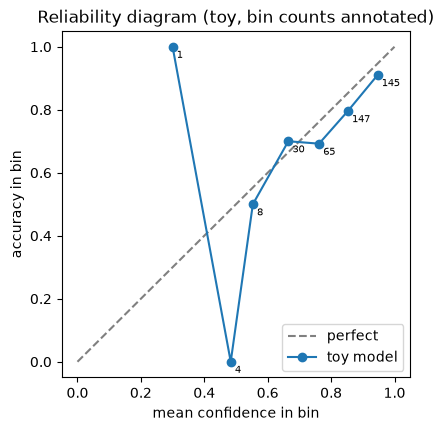

In [10]:
m = 400
conf = np.clip(rng.beta(8, 1.5, m), 0.3, 0.999)
true_p = 0.15 + 0.75 * conf  # the model is right less often than it claims
correct = rng.random(m) < true_p
brier = float(np.mean((conf - correct) ** 2))
bins = np.linspace(0, 1, 11)
idx = np.clip(np.digitize(conf, bins) - 1, 0, 9)
ece, rows = 0.0, []
for k in range(10):
    sel = idx == k
    if sel.any():
        gap = abs(correct[sel].mean() - conf[sel].mean())
        ece += sel.mean() * gap
        rows.append((bins[k], bins[k + 1], int(sel.sum()), conf[sel].mean(), correct[sel].mean()))
rel = pd.DataFrame(rows, columns=["lo", "hi", "n", "mean_conf", "accuracy"])
print(
    f"toy N={m}: Brier {brier:.4f}, ECE {ece:.4f}, mean confidence {conf.mean():.3f}, accuracy {correct.mean():.3f}"
)
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 1], [0, 1], "--", color="grey", label="perfect")
ax.plot(rel["mean_conf"], rel["accuracy"], "o-", label="toy model")
for _, row in rel.iterrows():
    ax.annotate(
        int(row["n"]),
        (row["mean_conf"], row["accuracy"]),
        fontsize=7,
        xytext=(3, -8),
        textcoords="offset points",
    )
ax.set_xlabel("mean confidence in bin")
ax.set_ylabel("accuracy in bin")
ax.set_title("Reliability diagram (toy, bin counts annotated)")
ax.legend()
RESULTS["calibration_toy"] = {"n": m, "brier": round(brier, 4), "ece_10_bins": round(ece, 4)}
rel.round(3)

Points under the diagonal mean over-confidence. With only 65 real items, most bins would hold a
handful of items, so a reliability diagram on the test set alone is mostly noise; calibration
has to be measured on the larger dev set, and the EXC-03 threshold chosen there.

## 10. Prevalence, base rate and positive predictive value

The dataset is more than half violations; a real stream has a few percent. **Prevalence**
changes what a flag means. Take the brief's numbers: 1 false positive in 9 clean receipts
(false-positive rate 11 %), 15 of 16 violations caught (sensitivity 94 %), and a 3 % base rate.
Per 10,000 receipts:

In [11]:
N, prev, sens, fpr = 10_000, 0.03, 15 / 16, 1 / 9
tp = N * prev * sens
fp = N * (1 - prev) * fpr
ppv = tp / (tp + fp)
RESULTS["base_rate"] = {
    "receipts": N,
    "prevalence": prev,
    "sensitivity": sens,
    "false_positive_rate": fpr,
    "true_positives": round(tp, 2),
    "false_positives": round(fp, 2),
    "ppv": round(ppv, 4),
}
print(f"true positives {tp:.2f}, false positives {fp:.2f}, PPV {ppv:.4f}")
print(f"=> about {fp / (tp + fp):.0%} of flags would be false alarms")
grid = pd.DataFrame(
    [
        (pv, N * pv * sens / (N * pv * sens + N * (1 - pv) * fpr))
        for pv in [0.01, 0.03, 0.05, 0.1, 0.25, 0.5]
    ],
    columns=["prevalence", "ppv"],
)
ds_prev = 16 / 28
ds_ppv = ds_prev * sens / (ds_prev * sens + (1 - ds_prev) * fpr)
print(
    f"at the dataset's prevalence ({ds_prev:.0%}, 16 of 28 in-scope receipts) PPV would be {ds_ppv:.3f}"
)
grid.round(3)

true positives 281.25, false positives 1077.78, PPV 0.2069
=> about 79% of flags would be false alarms
at the dataset's prevalence (57%, 16 of 28 in-scope receipts) PPV would be 0.918


,prevalence,ppv
0,0.01,0.079
1,0.03,0.207
2,0.05,0.308
3,0.10,0.484
4,0.25,0.738
5,0.50,0.894


At 3 % prevalence most flags would be false alarms (share printed above), even though the
same system looks good on this dataset's prevalence (printed below). And the 11 % false-positive rate
itself rests on 9 receipts (Wilson 2 %–43 %). Before production: measure the false-positive
rate on a large sample of real, mostly clean receipts.

## 11. Selection bias: picking the best of many variants on a small test set

If I try 20 prompt variants that are **all equally good** (true accuracy 85 %) and report the
best one's score on the same 65 items, the reported number is biased upward: I am selecting the
luckiest draw. The simulation shows how much. The fix: choose on a separate dev set with a
decision rule written before running, and run only the finalist on the test set.

In [12]:
def best_of(k: int, n_items: int, true_acc: float, reps: int = 4000) -> np.ndarray:
    draws = rng.binomial(n_items, true_acc, size=(reps, k)) / n_items
    return draws.max(axis=1)


rows = []
for k in [1, 3, 5, 10, 20, 40]:
    best = best_of(k, 65, 0.85)
    rows.append((k, best.mean(), best.mean() - 0.85, np.percentile(best, 95)))
sel = pd.DataFrame(rows, columns=["variants tried", "mean best score", "optimism", "95th pct best"])
RESULTS["selection_bias_sim"] = {
    "true_accuracy": 0.85,
    "n_items": 65,
    "optimism_best_of_20": round(
        float(sel.loc[sel["variants tried"] == 20, "optimism"].iloc[0]), 4
    ),
}
sel.round(3)

,variants tried,mean best score,optimism,95th pct best
0,1,0.851,0.001,0.923
1,3,0.887,0.037,0.938
2,5,0.899,0.049,0.938
3,10,0.915,0.065,0.954
4,20,0.927,0.077,0.954
5,40,0.937,0.087,0.969


The `optimism` column is how much better the winner looks than it is; it grows with the number
of variants tried. That is the whole argument for "decide on dev, report on test".

In [13]:
(EXP / "results" / "04_results.json").write_text(json.dumps(RESULTS, indent=2))
print(json.dumps(RESULTS, indent=2))

{
  "wilson_1_of_9": [
    0.0199,
    0.435
  ],
  "mcnemar": {
    "b": 7,
    "c": 2,
    "p_value": 0.179688,
    "test": "exact binomial, two-sided"
  },
  "min_detectable_difference_n65": 0.213,
  "min_detectable_difference_n65_detail": {
    "unpaired_two_proportion_at_0.85": 0.213,
    "paired_mcnemar": {
      "discordance_0.10": null,
      "discordance_0.15": 0.133,
      "discordance_0.20": 0.153,
      "discordance_0.30": 0.187
    },
    "alpha": 0.05,
    "power": 0.8
  },
  "calibration_toy": {
    "n": 400,
    "brier": 0.1514,
    "ece_10_bins": 0.0557
  },
  "base_rate": {
    "receipts": 10000,
    "prevalence": 0.03,
    "sensitivity": 0.9375,
    "false_positive_rate": 0.1111111111111111,
    "true_positives": 281.25,
    "false_positives": 1077.78,
    "ppv": 0.2069
  },
  "selection_bias_sim": {
    "true_accuracy": 0.85,
    "n_items": 65,
    "optimism_best_of_20": 0.0766
  }
}
